# Promotion Abuse Detection: GNN + Naive Bayes Ensemble

**Dataset:** Meituan *Public Promotion Abuse* (PPA), released with the PromoGuardian paper (`osf.io/rasje`).
**Task:** node classification. Given users (nodes) connected by relations (edges), decide which users are **promotion-abuse fraudsters**.

**Why this fits the "free-trial abuse" idea:** in both problems the abusers look like normal customers one at a time. What gives them away is *who they are connected to* (shared devices, addresses, coupons, timing). That is exactly what a graph model captures.

### Pipeline in this notebook
| # | Stage | What happens |
|---|-------|--------------|
| 1 | Inventory + load | List files, print the dataset `readme.md`, load `node.csv` and `edge.csv` |
| 2 | Auto-detect schema | Guess the ID / label / source / target / relation columns (you can override them) |
| 3 | Graph build | Clean edges, encode relation types, optionally sub-sample a manageable subgraph |
| 4 | Features | Node attributes + transaction aggregates + graph-structure features |
| 5 | Split | Stratified train / validation / test on labelled nodes |
| 6 | Model A | Gaussian **Naive Bayes** on tabular + structural features |
| 7 | Model B | Relation-aware **GraphSAGE-style GNN** (pure PyTorch, no extra graph library) |
| 8 | Ensemble | Weighted soft vote tuned on validation, plus an optional stacked version |
| 9 | Evaluation | Precision / Recall / F1 / PR-AUC / ROC-AUC, confusion matrix, error analysis |

> **First run:** execute the cells top to bottom. Cell 7 prints the dataset's own `readme.md` and the column lists. If the auto-detected columns (printed in section 2) are wrong, set the overrides in the **Configuration** cell and re-run.

## 0. Setup

In [1]:
import os, re, gc, json, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    precision_score, recall_score, f1_score, confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Pandas:", pd.__version__, "| NumPy:", np.__version__)

Pandas: 3.0.1 | NumPy: 2.4.2


In [2]:
# PyTorch is needed for the GNN. This cell only checks the environment.
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F

    torch.manual_seed(SEED)
    print("PyTorch version:", torch.__version__)
    print("CUDA available:", torch.cuda.is_available())
    if torch.cuda.is_available():
        print("CUDA version used by PyTorch:", torch.version.cuda)
        for gpu_id in range(torch.cuda.device_count()):
            print(f"GPU {gpu_id}:", torch.cuda.get_device_name(gpu_id))
        torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False
    DEVICE = None
    print("PyTorch is NOT installed. Install it before running the GNN section, e.g.:")
    print("    uv add torch scikit-learn scipy matplotlib pandas pyarrow")
    print("    (or: pip install torch)  - choose the CUDA build that matches your GPU if you have one.")

print("Training device:", DEVICE)

PyTorch version: 2.10.0+cpu
CUDA available: False
Training device: cpu


## Configuration

Everything you may want to change lives in this one cell. `None` means "auto-detect".

* **`MAX_NODES`**: the full PPA graph is huge (millions of users, tens of millions of edges). Training on all of it needs a lot of RAM. The notebook builds a smaller subgraph of about `MAX_NODES` nodes around randomly chosen labelled users and their neighbours. Set to `None` to use everything (only if you have the memory).
* **`TX_MAX_ROWS`**: each order file has ~20 million rows. They are streamed in chunks and cached, so the slow pass happens once. Use a small value first to check everything runs.
* **`PRESERVE_PREVALENCE`**: `True` keeps the natural fraud rate in the sample (honest precision numbers, but fewer fraudsters). `False` keeps more fraudsters, which makes learning easier but **inflates precision** compared with real life.

In [3]:
# ------------------------------- paths (match your project tree) -------------------------------
DATA_DIR    = Path("rasje-osfstorage-archive")
NODE_FILE   = DATA_DIR / "node.csv"
EDGE_FILE   = DATA_DIR / "edge.csv"
TX_DIR      = DATA_DIR / "Transactions"
README_FILE = DATA_DIR / "readme.md"
OUTPUT_DIR  = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ------------------------------- column overrides (None = auto-detect) -------------------------------
NODE_ID_COL   = None   # unique user / node id in node.csv
LABEL_COL     = None   # fraud label in node.csv (1 = abuser, 0 = normal)
EDGE_SRC_COL  = None   # source node column in edge.csv
EDGE_DST_COL  = None   # target node column in edge.csv
EDGE_REL_COL  = None   # relation type column in edge.csv (device / address / coupon ...)
TX_USER_COL   = None   # user id column inside the Transactions files

# If labels are NOT inside node.csv, point to a separate CSV that holds them:
EXTERNAL_LABEL_FILE   = None   # e.g. DATA_DIR / "labels.csv"
EXTERNAL_LABEL_ID_COL = None
EXTERNAL_LABEL_COL    = None

# ------------------------------- data size controls -------------------------------
EDGE_NROWS          = None      # e.g. 2_000_000 to read only the first rows of edge.csv while testing
USE_TRANSACTIONS    = True      # aggregate the Transactions folder into per-user features
TX_MAX_ROWS         = None      # e.g. 3_000_000 per file for a quick test run (None = read everything)
TX_CHUNK            = 2_000_000 # rows per chunk when streaming the big order files
FORCE_RECOMPUTE_TX  = False     # True = ignore the cached outputs/tx_feat_*.pkl files
MAX_NODES           = 300_000   # None = use the full graph
PRESERVE_PREVALENCE = True
MAX_RELATIONS       = 8         # keep the most frequent relation types; merge the rest into "other"

# ------------------------------- split -------------------------------
# "temporal": train/validation = users active in order_train.csv (week 1), test = users first seen in
#             order_test.csv (week 2). This mirrors the PromoGuardian paper and is the honest setting.
# "random"  : stratified random split of all labelled users (easier, less realistic).
SPLIT_MODE = "temporal"
VAL_FRAC_OF_TRAIN = 0.25        # share of the training pool held out for validation
TRAIN_FRAC = 0.60               # only used when SPLIT_MODE = "random"
VAL_FRAC   = 0.20               # only used when SPLIT_MODE = "random" (test = the rest)

# ------------------------------- GNN hyper-parameters -------------------------------
HIDDEN       = 128
N_LAYERS     = 2
DROPOUT      = 0.30
LR           = 5e-3
WEIGHT_DECAY = 1e-5
EPOCHS       = 300
PATIENCE     = 40

# ------------------------------- gradient boosting + label-aware graph features -------------------------------
# Adds "how many of my neighbours are KNOWN abusers / normal" as features for the boosting model.
# Only TRAIN labels are used (never validation/test labels), and these features are NOT given to the GNN
# (that would leak a node's own label back to it through message passing).
USE_LABEL_NEIGHBOR_FEATURES = True

print("Project folder  :", Path.cwd())
print("Dataset folder  :", DATA_DIR.resolve(), "| exists:", DATA_DIR.exists())

Project folder  : d:\LEARNING_HOW_TO_CODE\Public_offer_Abuse
Dataset folder  : D:\LEARNING_HOW_TO_CODE\Public_offer_Abuse\rasje-osfstorage-archive | exists: True


## 1. Dataset inventory and the dataset's own documentation

Always read the dataset's `readme.md` first. It normally describes each column and the meaning of every relation type.

In [4]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Folder not found: {DATA_DIR.resolve()}\n"
        "Make sure the notebook runs from the project root, or change DATA_DIR above."
    )

all_files = sorted(p for p in DATA_DIR.rglob("*") if p.is_file())
print(f"Files under {DATA_DIR}: {len(all_files)}\n")

shown_in_tx = 0
for p in all_files:
    size_mb = p.stat().st_size / 1024**2
    in_tx = TX_DIR in p.parents
    if in_tx:
        shown_in_tx += 1
        if shown_in_tx > 8:
            continue
    print(f"{str(p.relative_to(DATA_DIR)):<50} {size_mb:10.2f} MB")
if shown_in_tx > 8:
    print(f"... and {shown_in_tx - 8} more files inside Transactions/")

print("\n" + "=" * 90)
print("readme.md")
print("=" * 90)
if README_FILE.exists():
    print(README_FILE.read_text(encoding="utf-8", errors="replace")[:8000])
else:
    print("(no readme.md found)")

Files under rasje-osfstorage-archive: 5

edge.csv                                               644.08 MB
node.csv                                               135.78 MB
readme.md                                                0.00 MB
Transactions\order_test.csv                           1487.14 MB
Transactions\order_train.csv                          1549.91 MB

readme.md
## Dataset
### Graph
The user IDs, labels, and a matrix filled with all ones that represents the initial features of user nodes are saved in the `node.csv` file.
Each row in the `edge.csv` file represents an edge in the graph. The columns `src` and `dst` represent the node IDs of the two endpoints of this edge, and `r1`...`r8` represent the weights of the eight types of relationships of this edge.
This graph is obtained by filtering the original orders of the test set, and the original orders are stored in the folder named `Transactions`.
### orders
The `Transactions` folder stores the original orders used for train

## 2. Load `node.csv` and `edge.csv`

In [5]:
def read_table(path, nrows=None):
    """Read a CSV. If the first row looks like data (no header), reload without a header."""
    df = pd.read_csv(path, nrows=nrows, low_memory=False)

    def _is_num(x):
        try:
            float(str(x))
            return True
        except ValueError:
            return False

    if all(_is_num(c) for c in df.columns):
        print(f"[{path.name}] header row looks numeric -> reloading with header=None")
        df = pd.read_csv(path, header=None, nrows=nrows, low_memory=False)
        df.columns = [f"col_{i}" for i in range(df.shape[1])]
    return df


t0 = time.time()
nodes = read_table(NODE_FILE)
edges = read_table(EDGE_FILE, nrows=EDGE_NROWS)
print(f"Loaded in {time.time() - t0:.1f}s")

for name, df in [("node.csv", nodes), ("edge.csv", edges)]:
    print("\n" + "-" * 90)
    print(f"{name}: shape = {df.shape} | memory = {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
    print("-" * 90)
    display(df.head())
    print(df.dtypes.to_string())

Loaded in 8.7s

------------------------------------------------------------------------------------------
node.csv: shape = (3267961, 10) | memory = 249.3 MB
------------------------------------------------------------------------------------------


,id,label,vec_0,vec_1,vec_2,vec_3,vec_4,vec_5,vec_6,vec_7
0,0,-1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,1,-1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,2,-1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
3,3,-1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,4,-1,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


id         int64
label      int64
vec_0    float64
vec_1    float64
vec_2    float64
vec_3    float64
vec_4    float64
vec_5    float64
vec_6    float64
vec_7    float64

------------------------------------------------------------------------------------------
edge.csv: shape = (10012449, 10) | memory = 763.9 MB
------------------------------------------------------------------------------------------


,src,dst,r1_score,r2_score,r3_score,r4_score,r5_score,r6_score,r7_score,r8_score
0,450,984,0.0,0.0,0.0,0.0,0.0,0.731059,0.731059,0.0
1,578,1043,0.0,0.0,0.0,0.0,0.0,0.635049,0.000000,0.0
2,637,1198,0.0,0.0,0.0,0.0,0.0,0.440399,0.000000,0.0
3,89,1294,0.0,0.0,0.0,0.0,0.0,0.440399,0.000000,0.0
4,467,1411,0.0,0.0,0.0,0.0,0.0,0.440399,0.000000,0.0


src           int64
dst           int64
r1_score    float64
r2_score    float64
r3_score    float64
r4_score    float64
r5_score    float64
r6_score    float64
r7_score    float64
r8_score    float64


In [6]:
# ----------------------------- automatic schema detection -----------------------------
def _norm(s):
    return str(s).strip().lower().replace(" ", "_")

def find_col(columns, exact=(), contains=(), exclude=()):
    """Return the first column that equals one of `exact` names, else contains one of `contains` fragments."""
    lookup = {_norm(c): c for c in columns if c not in exclude}
    for name in exact:
        if name in lookup:
            return lookup[name]
    for frag in contains:
        for key, col in lookup.items():
            if frag in key:
                return col
    return None

node_cols, edge_cols = list(nodes.columns), list(edges.columns)

NODE_ID = NODE_ID_COL or find_col(
    node_cols, exact=["node_id", "user_id", "uid", "userid", "id", "node", "user", "nid"],
    contains=["user", "node", "id"]) or node_cols[0]

LABEL = LABEL_COL or find_col(
    node_cols, exact=["label", "labels", "is_fraud", "fraud", "fraudster", "is_fraudster", "y",
                      "target", "class", "is_abuse", "abuse", "flag"],
    contains=["label", "fraud", "abuse", "target"], exclude=[NODE_ID])

EDGE_REL = EDGE_REL_COL or find_col(
    edge_cols, exact=["relation", "rel", "relation_type", "edge_type", "type", "etype", "rel_type", "r", "edge_label"],
    contains=["relation", "rel", "type"])

EDGE_TIME = find_col(edge_cols, exact=["time", "timestamp", "ts", "date", "datetime", "create_time", "order_time"],
                     contains=["time", "date"], exclude=[EDGE_REL] if EDGE_REL else [])

EDGE_REL_MULTI = [] if EDGE_REL else [c for c in edge_cols if re.fullmatch(r"r\d+", _norm(c))]

SRC = EDGE_SRC_COL or find_col(
    edge_cols, exact=["src", "source", "src_id", "source_id", "from", "from_id", "u", "user1", "user_1", "node1",
                      "node_1", "id1", "id_1", "user_a", "start"],
    contains=["src", "source", "from"], exclude=[c for c in (EDGE_REL, EDGE_TIME, *EDGE_REL_MULTI) if c])

DST = EDGE_DST_COL or find_col(
    edge_cols, exact=["dst", "dest", "destination", "dst_id", "target", "target_id", "to", "to_id", "v", "user2",
                      "user_2", "node2", "node_2", "id2", "id_2", "user_b", "end"],
    contains=["dst", "dest", "target", "to_"], exclude=[c for c in (SRC, EDGE_REL, EDGE_TIME, *EDGE_REL_MULTI) if c])

if SRC is None or DST is None:                    # fall back to the first two non-relation columns
    rest = [c for c in edge_cols if c not in (EDGE_REL, EDGE_TIME, *EDGE_REL_MULTI)]
    SRC = SRC or rest[0]
    DST = DST or [c for c in rest if c != SRC][0]
    print("WARNING: edge endpoints not recognised by name; using the first two columns:", SRC, DST)

EXT_LABELS = None
if EXTERNAL_LABEL_FILE is not None:
    EXT_LABELS = read_table(Path(EXTERNAL_LABEL_FILE))
    EXT_ID = EXTERNAL_LABEL_ID_COL or find_col(list(EXT_LABELS.columns), exact=["node_id", "user_id", "id"],
                                               contains=["id", "user"]) or EXT_LABELS.columns[0]
    EXT_LAB = EXTERNAL_LABEL_COL or find_col(list(EXT_LABELS.columns), exact=["label", "is_fraud", "fraud"],
                                             contains=["label", "fraud"], exclude=[EXT_ID])
    LABEL = EXT_LAB

detected = pd.DataFrame({
    "role": ["node id", "label", "edge source", "edge target", "edge relation (single column)",
             "edge relation (multi columns r1..rK)", "edge time"],
    "column": [NODE_ID, LABEL, SRC, DST, EDGE_REL, ", ".join(EDGE_REL_MULTI) or None, EDGE_TIME],
})
display(detected)

if LABEL is None:
    raise ValueError(
        "Could not find a label column in node.csv.\n"
        f"node.csv columns : {node_cols}\n"
        "Set LABEL_COL in the Configuration cell, or use EXTERNAL_LABEL_FILE if labels live in another file "
        "(check the readme printed above and the Transactions folder)."
    )

,role,column
0,node id,id
1,label,label
2,edge source,src
3,edge target,dst
4,edge relation (single column),NaN
5,edge relation (multi columns r1..rK),NaN
6,edge time,NaN


## 3. Unify node IDs and parse labels

Edge endpoints may reference users that are missing from `node.csv`; they are added as **unlabelled** nodes (they still carry graph information). Every node gets a compact integer index `0..N-1`.

In [7]:
nodes = nodes.drop_duplicates(subset=NODE_ID, keep="first").reset_index(drop=True)
edges = edges.dropna(subset=[SRC, DST]).reset_index(drop=True)

ALL_INT = all(pd.api.types.is_integer_dtype(s) for s in (nodes[NODE_ID], edges[SRC], edges[DST]))

def norm_str(s):
    if pd.api.types.is_float_dtype(s) and (s.dropna() % 1 == 0).all():
        s = s.astype("Int64")
    return s.astype(str)

def conv_ids(s):
    """Convert an id column to a common representation. Returns (values, valid_mask)."""
    if ALL_INT:
        v = pd.to_numeric(s, errors="coerce")
        ok = v.notna().to_numpy()
        return v.fillna(-1).to_numpy(np.int64), ok
    return norm_str(s).to_numpy(dtype=object), np.ones(len(s), dtype=bool)

nid, _ = conv_ids(nodes[NODE_ID])
sid, _ = conv_ids(edges[SRC])
did, _ = conv_ids(edges[DST])

index = pd.Index(pd.unique(np.concatenate([nid, sid, did])))      # id -> position
N = len(index)
node_pos = index.get_indexer(nid)
src_i = index.get_indexer(sid).astype(np.int64)
dst_i = index.get_indexer(did).astype(np.int64)

print(f"ID mode           : {'integer' if ALL_INT else 'string'}")
print(f"Nodes in node.csv : {len(nodes):,}")
print(f"Total nodes       : {N:,}  (extra nodes only seen in edges: {N - len(nodes):,})")
print(f"Raw edge rows     : {len(src_i):,}")

# ------------------------------- labels -------------------------------
def parse_labels(s):
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() < 0.5:                                   # text labels
        low = s.astype(str).str.strip().str.lower()
        pos = {"1", "true", "yes", "fraud", "fraudster", "abuse", "abuser", "bad", "positive"}
        neg = {"0", "false", "no", "normal", "legit", "benign", "good", "negative"}
        out = np.full(len(s), -1, dtype=np.int64)
        out[low.isin(pos).to_numpy()] = 1
        out[low.isin(neg).to_numpy()] = 0
        return out
    return np.where(num.isin([0, 1]), num.fillna(-1), -1).astype(np.int64)

y = np.full(N, -1, dtype=np.int64)                                 # -1 = unlabelled
if EXT_LABELS is not None:
    ext_ids, ok = conv_ids(EXT_LABELS[EXT_ID])
    ext_pos = index.get_indexer(ext_ids[ok])
    parsed = parse_labels(EXT_LABELS.loc[ok, EXT_LAB])
    keep = ext_pos >= 0
    y[ext_pos[keep]] = parsed[keep]
    raw_label_counts = EXT_LABELS[EXT_LAB].value_counts(dropna=False)
else:
    y[node_pos] = parse_labels(nodes[LABEL])
    raw_label_counts = nodes[LABEL].value_counts(dropna=False)

print("\nRaw label values:")
print(raw_label_counts.head(10).to_string())
print(f"\nLabelled nodes : {(y >= 0).sum():,}")
print(f"  abusers  (1) : {(y == 1).sum():,}")
print(f"  normal   (0) : {(y == 0).sum():,}")
print(f"  unlabelled   : {(y < 0).sum():,}")
if (y == 1).sum() == 0:
    raise ValueError("No positive (1) labels found. Check LABEL_COL and the raw label values printed above.")

# node attribute table aligned to the N-node index (NaN for nodes that are not in node.csv)
drop_cols = [c for c in (NODE_ID, LABEL) if c in nodes.columns]
node_feat = nodes.drop(columns=drop_cols)
node_feat.index = node_pos
node_feat = node_feat.reindex(range(N))
print("Node attribute columns:", list(node_feat.columns))

del nid, sid, did
gc.collect();

ID mode           : integer
Nodes in node.csv : 3,267,961
Total nodes       : 3,267,961  (extra nodes only seen in edges: 0)
Raw edge rows     : 10,012,449

Raw label values:
label
-1    2962344
 0     237084
 1      68533

Labelled nodes : 305,617
  abusers  (1) : 68,533
  normal   (0) : 237,084
  unlabelled   : 2,962,344
Node attribute columns: ['vec_0', 'vec_1', 'vec_2', 'vec_3', 'vec_4', 'vec_5', 'vec_6', 'vec_7']


## 4. Encode relation types and clean the edge list

PPA connects users through **eight relation types** (the paper lists things like shared group chat, promotion, coupon, offline dealer "header"...). Depending on how `edge.csv` stores this, relations are either one `relation` column, or several indicator columns `r1..r8`. Both layouts are handled. Edges are treated as **undirected**.

In [8]:
if EDGE_REL:                                           # layout A: one relation column
    rel_raw = edges[EDGE_REL]
    vc = rel_raw.value_counts()
    keep_rel = list(vc.index[:MAX_RELATIONS - 1]) if len(vc) > MAX_RELATIONS else list(vc.index)
    rel_map = {r: i for i, r in enumerate(keep_rel)}
    rel_e = rel_raw.map(rel_map)
    has_other = bool(rel_e.isna().any())
    rel_e = rel_e.fillna(len(keep_rel)).to_numpy(np.int64)
    src_e, dst_e = src_i, dst_i
    rel_names = [str(r) for r in keep_rel] + (["other"] if has_other else [])

elif EDGE_REL_MULTI:                                   # layout B: indicator columns r1..r8
    s_parts, d_parts, r_parts = [], [], []
    any_rel = np.zeros(len(src_i), dtype=bool)
    for k, col in enumerate(EDGE_REL_MULTI):
        v = pd.to_numeric(edges[col], errors="coerce")
        m = (v.notna() & (v != 0)).to_numpy()
        any_rel |= m
        s_parts.append(src_i[m]); d_parts.append(dst_i[m]); r_parts.append(np.full(int(m.sum()), k, dtype=np.int64))
    rel_names = list(EDGE_REL_MULTI)
    if (~any_rel).any():                               # edges with no relation flag
        s_parts.append(src_i[~any_rel]); d_parts.append(dst_i[~any_rel])
        r_parts.append(np.full(int((~any_rel).sum()), len(rel_names), dtype=np.int64))
        rel_names.append("other")
    src_e, dst_e, rel_e = np.concatenate(s_parts), np.concatenate(d_parts), np.concatenate(r_parts)

else:                                                  # layout C: no relation info at all
    src_e, dst_e = src_i, dst_i
    rel_e = np.zeros(len(src_i), dtype=np.int64)
    rel_names = ["all"]

R = len(rel_names)
no_loop = src_e != dst_e
src_e, dst_e, rel_e = src_e[no_loop], dst_e[no_loop], rel_e[no_loop]

print(f"Relation types (R = {R}): {rel_names}")
print(f"Edge records after cleaning: {len(src_e):,}   (self-loops removed: {int((~no_loop).sum()):,})")
print(pd.Series(rel_e).map(dict(enumerate(rel_names))).value_counts().to_string())

del edges, src_i, dst_i
gc.collect();

Relation types (R = 1): ['all']
Edge records after cleaning: 10,012,449   (self-loops removed: 0)
all    10012449


## 5. Transaction files: per-user behaviour features, one set per week

`Transactions/order_train.csv` (week 1) and `order_test.csv` (week 2) each hold ~20 million order lines:

| column | meaning (inferred from the data) |
|---|---|
| `order_time` | anonymised order date (year is masked, e.g. `1000-05-25`) |
| `sku_id` | product |
| `id` | **user id** (same user repeats the same `r*` values across orders) |
| `r1..r8` | the user's value for each of the 8 relation types on that order (`NaN` = relation not present). Two users with the **same** `r_k` value are linked through relation *k* |

The files are streamed in chunks (they do not fit comfortably in RAM) and reduced to **one row per user per week**:

* volume: number of orders, active days, busiest-day share, distinct SKUs
* relation presence: share of orders that carry each `r_k`
* **group features** (the key fraud signal): for each relation, how many *distinct users share the same value*. Abuse rings share values with many other accounts, so `grp_max` / `grp_mean` are large for them.

Features for week-1 users come from `order_train.csv`; features for week-2 users come from `order_test.csv`. Results are cached in `outputs/`, so the slow pass runs only once.

In [9]:
def day_index(s):
    """order_time -> numeric day index. Year is masked in PPA, so use (month-1)*31 + day."""
    if pd.api.types.is_numeric_dtype(s):
        return s.to_numpy(dtype=float)
    m = s.astype(str).str.extract(r"(\d{1,4})-(\d{1,2})-(\d{1,2})")
    return ((pd.to_numeric(m[1], errors="coerce") - 1) * 31 + pd.to_numeric(m[2], errors="coerce")).to_numpy(float)


def aggregate_orders(path, tag, nrows=None):
    cache = OUTPUT_DIR / f"tx_feat_{tag}.pkl"
    sig = dict(N=int(N), nrows=nrows, edge_nrows=EDGE_NROWS, file=path.name, size=path.stat().st_size)
    if cache.exists() and not FORCE_RECOMPUTE_TX:
        obj = pd.read_pickle(cache)
        if obj.get("sig") == sig:
            print(f"[{tag}] loaded cached features from {cache}")
            return obj["feat"], obj["active"]

    t0 = time.time()
    head = pd.read_csv(path, nrows=5)
    cols = list(head.columns)
    c_user = TX_USER_COL or find_col(cols, exact=["id", "user_id", "uid", "userid", "buyer_id", "customer_id"],
                                     contains=["user", "uid", "buyer", "customer"])
    c_sku = find_col(cols, exact=["sku_id", "sku", "item_id", "product_id"], contains=["sku", "item", "product"],
                     exclude=[c_user])
    c_time = find_col(cols, exact=["order_time", "time", "date", "timestamp"], contains=["time", "date"],
                      exclude=[c_user])
    c_rels = sorted([c for c in cols if re.fullmatch(r"r\d+", _norm(c))], key=lambda c: int(_norm(c)[1:]))
    if c_user is None:
        print(f"[{tag}] could not find the user column in {cols}; set TX_USER_COL"); return None, None
    print(f"[{tag}] user={c_user} sku={c_sku} time={c_time} relations={c_rels}")

    usecols = [c for c in [c_user, c_sku, c_time, *c_rels] if c]
    user_parts, day_parts = [], []
    sku_pairs = None
    rel_pairs = {c: None for c in c_rels}
    active = np.zeros(N, dtype=bool)
    n_rows = 0

    reader = pd.read_csv(path, usecols=usecols, chunksize=TX_CHUNK, nrows=nrows, low_memory=False)
    for ci, chunk in enumerate(reader):
        n_rows += len(chunk)
        uid, ok = conv_ids(chunk[c_user])
        pos = index.get_indexer(uid)
        ok = ok & (pos >= 0)
        if not ok.any():
            continue
        chunk, pos = chunk.loc[ok], pos[ok]
        active[pos] = True

        d = pd.DataFrame({"u": pos, "n": np.int32(1)})
        for j, c in enumerate(c_rels):
            d[f"nn{j}"] = chunk[c].notna().to_numpy().astype(np.int32)
        user_parts.append(d.groupby("u", sort=False).sum())

        if c_time:
            dd = pd.DataFrame({"u": pos, "day": day_index(chunk[c_time])}).dropna()
            day_parts.append(dd.groupby(["u", "day"], sort=False).size().rename("n").reset_index())

        if c_sku:
            sk = pd.DataFrame({"u": pos, "k": chunk[c_sku].to_numpy()}).dropna().drop_duplicates()
            sku_pairs = sk if sku_pairs is None else pd.concat([sku_pairs, sk]).drop_duplicates()

        for c in c_rels:
            v = chunk[c]
            m = v.notna().to_numpy()
            pr = pd.DataFrame({"u": pos[m], "k": v.to_numpy()[m]}).drop_duplicates()
            rel_pairs[c] = pr if rel_pairs[c] is None else pd.concat([rel_pairs[c], pr]).drop_duplicates()

        if len(user_parts) >= 5:                                   # keep memory bounded
            user_parts = [pd.concat(user_parts).groupby(level=0).sum()]
            if day_parts:
                day_parts = [pd.concat(day_parts).groupby(["u", "day"], sort=False)["n"].sum().reset_index()]
        print(f"   [{tag}] chunk {ci + 1}: {n_rows:,} rows read, {time.time() - t0:.0f}s", end="\r")
    print()

    if not user_parts:
        print(f"[{tag}] none of the transaction users matched the node ids -> check TX_USER_COL / id formats")
        return None, None

    ua = pd.concat(user_parts).groupby(level=0).sum()
    feat = pd.DataFrame(index=ua.index)
    feat["tx_n_orders"] = ua["n"]
    for j, c in enumerate(c_rels):
        feat[f"tx_{_norm(c)}_rate"] = ua[f"nn{j}"] / ua["n"]

    if day_parts:
        da = pd.concat(day_parts).groupby(["u", "day"], sort=False)["n"].sum().reset_index()
        g = da.groupby("u")
        feat["tx_active_days"] = g["day"].nunique()
        feat["tx_max_orders_day"] = g["n"].max()
        feat["tx_day_span"] = g["day"].max() - g["day"].min()
        feat["tx_first_day"] = g["day"].min()
        feat["tx_busiest_day_share"] = feat["tx_max_orders_day"] / feat["tx_n_orders"]
    if sku_pairs is not None:
        feat["tx_n_skus"] = sku_pairs.groupby("u").size()
        feat["tx_orders_per_sku"] = feat["tx_n_orders"] / feat["tx_n_skus"]

    for c in c_rels:                                               # group-size features
        pr = rel_pairs[c]
        if pr is None or pr.empty:
            continue
        pr = pr.assign(g=pr.groupby("k")["u"].transform("size").to_numpy())
        rn = _norm(c)
        feat[f"tx_{rn}_n_values"] = pr.groupby("u").size()
        feat[f"tx_{rn}_grp_max"] = pr.groupby("u")["g"].max()
        feat[f"tx_{rn}_grp_mean"] = pr.groupby("u")["g"].mean()

    feat = feat.fillna(0).astype(np.float32)
    pd.to_pickle(dict(sig=sig, feat=feat, active=active), cache)
    print(f"[{tag}] {n_rows:,} rows -> {len(feat):,} users x {feat.shape[1]} features in {time.time() - t0:.0f}s (cached)")
    return feat, active


tx_train_feat = tx_test_feat = tx_train_active = tx_test_active = None
if USE_TRANSACTIONS and TX_DIR.exists():
    tx_files = sorted(TX_DIR.rglob("*.csv"))
    train_files = [f for f in tx_files if "train" in f.name.lower()]
    test_files = [f for f in tx_files if "test" in f.name.lower()]
    print("Transaction files:", [f.name for f in tx_files])
    if train_files:
        tx_train_feat, tx_train_active = aggregate_orders(train_files[0], "train", TX_MAX_ROWS)
    if test_files:
        tx_test_feat, tx_test_active = aggregate_orders(test_files[0], "test", TX_MAX_ROWS)
    if tx_train_feat is not None:
        display(tx_train_feat.describe().T.head(40))
else:
    print("Transactions are not used (USE_TRANSACTIONS=False or folder not found).")

Transaction files: ['order_test.csv', 'order_train.csv']
[train] loaded cached features from outputs\tx_feat_train.pkl
[test] loaded cached features from outputs\tx_feat_test.pkl


,count,mean,std,min,25%,50%,75%,max
tx_n_orders,3267961.0,6.000206e+00,5.636043,1.000,2.000000e+00,4.0,8.000000e+00,263.0
tx_r1_rate,3267961.0,9.926462e-01,0.080281,0.000,1.000000e+00,1.0,1.000000e+00,1.0
tx_r2_rate,3267961.0,0.000000e+00,0.000000,0.000,0.000000e+00,0.0,0.000000e+00,0.0
tx_r3_rate,3267961.0,9.999257e-01,0.006736,0.000,1.000000e+00,1.0,1.000000e+00,1.0
tx_r4_rate,3267961.0,0.000000e+00,0.000000,0.000,0.000000e+00,0.0,0.000000e+00,0.0
tx_r5_rate,3267961.0,0.000000e+00,0.000000,0.000,0.000000e+00,0.0,0.000000e+00,0.0
tx_r6_rate,3267961.0,5.328538e-01,0.310327,0.000,3.333333e-01,0.5,7.500000e-01,1.0
tx_r7_rate,3267961.0,9.999257e-01,0.006736,0.000,1.000000e+00,1.0,1.000000e+00,1.0
tx_r8_rate,3267961.0,9.910818e-01,0.087792,0.000,1.000000e+00,1.0,1.000000e+00,1.0
tx_active_days,3267961.0,2.698535e+00,1.760520,1.000,1.000000e+00,2.0,4.000000e+00,8.0


## 6. Sub-sample a manageable graph (optional)

If the graph has more than `MAX_NODES` nodes, pick random labelled seed users, add their neighbours, and keep the induced subgraph. Neighbours of the seeds stay in the graph (even unlabelled ones) because the GNN needs them for message passing.

In [10]:
def subsample_nodes(y, src, dst, max_nodes, preserve_prevalence, seed):
    rng = np.random.default_rng(seed)
    n = len(y)
    labeled = np.where(y >= 0)[0]
    pos, neg = labeled[y[labeled] == 1], labeled[y[labeled] == 0]
    budget = max_nodes // 2
    if preserve_prevalence:
        seeds = rng.choice(labeled, min(len(labeled), budget), replace=False)
    else:
        k_pos = min(len(pos), budget // 3)
        k_neg = min(len(neg), budget - k_pos)
        seeds = np.concatenate([rng.choice(pos, k_pos, replace=False), rng.choice(neg, k_neg, replace=False)])
    is_seed = np.zeros(n, dtype=bool)
    is_seed[seeds] = True
    nbrs = np.unique(np.concatenate([dst[is_seed[src]], src[is_seed[dst]]]))
    nbrs = nbrs[~is_seed[nbrs]]
    room = max_nodes - len(seeds)
    if len(nbrs) > room:
        nbrs = rng.choice(nbrs, room, replace=False)
    return np.sort(np.concatenate([seeds, nbrs]))


def remap_tx(feat, active, old2new, keep):
    if feat is None:
        return None, None
    new = old2new[feat.index.to_numpy()]
    m = new >= 0
    feat = feat.loc[m].copy()
    feat.index = new[m]
    return feat, active[keep]


if MAX_NODES is not None and N > MAX_NODES:
    keep = subsample_nodes(y, src_e, dst_e, MAX_NODES, PRESERVE_PREVALENCE, SEED)
    old2new = np.full(N, -1, dtype=np.int64)
    old2new[keep] = np.arange(len(keep))
    m = (old2new[src_e] >= 0) & (old2new[dst_e] >= 0)
    src_e, dst_e, rel_e = old2new[src_e[m]], old2new[dst_e[m]], rel_e[m]
    y = y[keep]
    node_feat = node_feat.iloc[keep].reset_index(drop=True)
    index = index[keep]
    tx_train_feat, tx_train_active = remap_tx(tx_train_feat, tx_train_active, old2new, keep)
    tx_test_feat, tx_test_active = remap_tx(tx_test_feat, tx_test_active, old2new, keep)
    print(f"Sub-sampled graph: {N:,} -> {len(keep):,} nodes, {len(src_e):,} edge records")
    N = len(keep)
    if (y == 1).sum() < 200:
        print("WARNING: fewer than 200 abusers in the sample. Increase MAX_NODES or set PRESERVE_PREVALENCE=False "
              "(then remember precision is inflated).")
else:
    print(f"Using the full graph: {N:,} nodes, {len(src_e):,} edge records")

print(f"Labelled: {(y >= 0).sum():,} | abusers: {(y == 1).sum():,} "
      f"({100 * (y == 1).sum() / max((y >= 0).sum(), 1):.2f}% of labelled)")

Sub-sampled graph: 3,267,961 -> 300,000 nodes, 1,518,103 edge records
Labelled: 257,230 | abusers: 58,390 (22.70% of labelled)


## 7. Build the graph and explore it

Nodes: 300,000 | unique undirected pairs: 1,518,103 | isolated nodes: 0.2%
Degree: mean 10.1, median 7, max 264


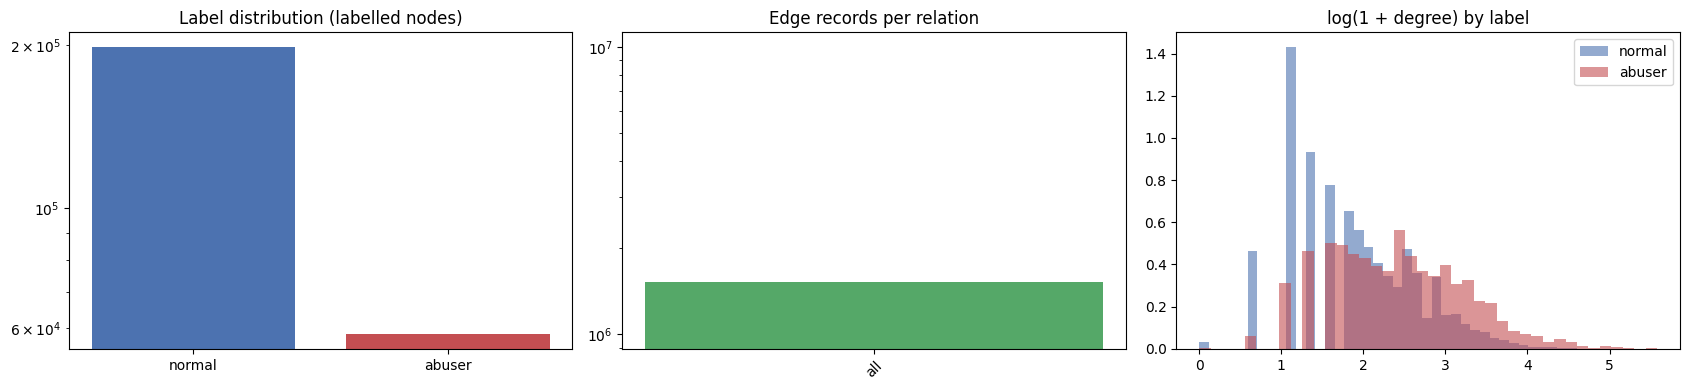


Median degree by label:
normal     5.0
abuser    10.0


In [11]:
# undirected, de-duplicated edges with multiplicity per relation
lo, hi = np.minimum(src_e, dst_e), np.maximum(src_e, dst_e)
e = (pd.DataFrame({"lo": lo, "hi": hi, "rel": rel_e})
       .groupby(["lo", "hi", "rel"], sort=False).size().rename("w").reset_index())
pairs = e[["lo", "hi"]].drop_duplicates()
del lo, hi, src_e, dst_e, rel_e
gc.collect()

deg_all = np.bincount(pairs["lo"], minlength=N) + np.bincount(pairs["hi"], minlength=N)
wdeg = np.bincount(e["lo"], weights=e["w"], minlength=N) + np.bincount(e["hi"], weights=e["w"], minlength=N)
deg_rel = np.zeros((N, R))
for r in range(R):
    sub = e[e["rel"] == r]
    deg_rel[:, r] = np.bincount(sub["lo"], minlength=N) + np.bincount(sub["hi"], minlength=N)

print(f"Nodes: {N:,} | unique undirected pairs: {len(pairs):,} | isolated nodes: {(deg_all == 0).mean() * 100:.1f}%")
print(f"Degree: mean {deg_all.mean():.1f}, median {np.median(deg_all):.0f}, max {deg_all.max():,}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
lab = pd.Series(y[y >= 0]).map({0: "normal", 1: "abuser"}).value_counts()
ax[0].bar(lab.index, lab.values, color=["#4c72b0", "#c44e52"][: len(lab)])
ax[0].set_title("Label distribution (labelled nodes)"); ax[0].set_yscale("log")

rel_counts = e.groupby("rel")["w"].sum().reindex(range(R)).fillna(0)
ax[1].bar([rel_names[i] for i in range(R)], rel_counts.values, color="#55a868")
ax[1].set_title("Edge records per relation"); ax[1].set_yscale("log"); ax[1].tick_params(axis="x", rotation=45)

for lbl, name, col in [(0, "normal", "#4c72b0"), (1, "abuser", "#c44e52")]:
    d = np.log1p(deg_all[y == lbl])
    if len(d):
        ax[2].hist(d, bins=40, alpha=0.6, density=True, label=name, color=col)
ax[2].set_title("log(1 + degree) by label"); ax[2].legend()
plt.tight_layout(); plt.show()

print("\nMedian degree by label:")
print(pd.Series({"normal": np.median(deg_all[y == 0]) if (y == 0).any() else np.nan,
                 "abuser": np.median(deg_all[y == 1])}).to_string())

## 8. Train / validation / test split

**Temporal split (default):**
* **Train + validation:** labelled users active in week 1 (`order_train.csv`). 25% of them become the validation set.
* **Test:** labelled users that appear in week 2 (`order_test.csv`) and **not** in week 1, i.e. genuinely "future" users.
* **Fallback (`temporal_disjoint`):** if the same users shop in both weeks, "new in week 2" is nearly empty and the test set would contain no abusers. The notebook then splits the *users* into disjoint groups: train/validation users are described by their week-1 behaviour, test users by their week-2 behaviour. Users never appear on both sides.

The diagnostic cell right before the split prints how many labelled users and abusers fall into each activity group, so you can see which case applies.

The validation set is used for early stopping, the ensemble weight and the decision threshold. The test set is touched only for the final report.

In [12]:
# ---- diagnostic: where do the labelled users and abusers live? --------------------------------------
print(f"Nodes: {N:,} | labelled: {(y >= 0).sum():,} | abusers: {(y == 1).sum():,}")
if tx_train_active is None or tx_test_active is None:
    print("Transaction activity is missing (see section 5 output).")
else:
    groups = {
        "active in week 1": tx_train_active,
        "active in week 2": tx_test_active,
        "week 2 only": tx_test_active & ~tx_train_active,
        "both weeks": tx_train_active & tx_test_active,
        "no activity in either week": ~(tx_train_active | tx_test_active),
    }
    diag = pd.DataFrame({
        "users": {k: int(v.sum()) for k, v in groups.items()},
        "labelled": {k: int((v & (y >= 0)).sum()) for k, v in groups.items()},
        "abusers": {k: int((v & (y == 1)).sum()) for k, v in groups.items()},
    })
    display(diag)
    if TX_MAX_ROWS is not None:
        print(f"NOTE: TX_MAX_ROWS = {TX_MAX_ROWS:,} reads only the first rows of each order file, "
              "which may cover just a slice of the users.")

Nodes: 300,000 | labelled: 257,230 | abusers: 58,390


,users,labelled,abusers
active in week 1,300000,257230,58390
active in week 2,300000,257230,58390
week 2 only,0,0,0
both weeks,300000,257230,58390
no activity in either week,0,0,0


In [13]:
labeled = y >= 0
have_tx = tx_train_active is not None and tx_test_active is not None
mode = SPLIT_MODE if (SPLIT_MODE != "temporal" or have_tx) else "random"
if mode != SPLIT_MODE:
    print("Temporal split needs both order_train.csv and order_test.csv -> falling back to a random split.")

MIN_TEST_ABUSERS = 30

def n_pos(idx):
    return int((y[idx] == 1).sum())

def safe_split(idx, test_size):
    """Stratified split when possible, plain random split if a class is too small."""
    try:
        return train_test_split(idx, test_size=test_size, stratify=y[idx], random_state=SEED)
    except ValueError:
        return train_test_split(idx, test_size=test_size, random_state=SEED)

if mode == "temporal":
    only_train = np.where(labeled & tx_train_active & ~tx_test_active)[0]
    only_test = np.where(labeled & tx_test_active & ~tx_train_active)[0]
    both = np.where(labeled & tx_train_active & tx_test_active)[0]
    print("Labelled users by activity (abusers in brackets):")
    print(f"  week 1 only : {len(only_train):>9,}  ({n_pos(only_train):,})")
    print(f"  week 2 only : {len(only_test):>9,}  ({n_pos(only_test):,})")
    print(f"  both weeks  : {len(both):>9,}  ({n_pos(both):,})")

    if n_pos(only_test) >= MIN_TEST_ABUSERS:
        # strict temporal split: test = users who first appear in week 2; overlap users stay in TRAIN
        train_pool = np.where(labeled & tx_train_active)[0]
        test_pool = only_test
    else:
        # Same users shop in both weeks, so "new in week 2" is (almost) empty. Split the users instead:
        # users are disjoint between train and test, but test users use their WEEK-2 behaviour.
        print(f"\nOnly {n_pos(only_test)} abusers appear in week 2 alone (need {MIN_TEST_ABUSERS}).")
        print("-> using 'temporal_disjoint': users are split into disjoint groups; train/validation users are "
              "described by week-1 behaviour, test users by week-2 behaviour.")
        mode = "temporal_disjoint"
        if len(both) > 0:
            b_train, b_test = safe_split(both, 0.30)
        else:
            b_train = b_test = np.array([], dtype=np.int64)
        train_pool = np.concatenate([only_train, b_train]).astype(np.int64)
        test_pool = np.concatenate([only_test, b_test]).astype(np.int64)

    tr_idx, va_idx = safe_split(train_pool, VAL_FRAC_OF_TRAIN)
    te_idx = test_pool
else:
    lab_idx = np.where(labeled)[0]
    tr_idx, tmp = train_test_split(lab_idx, train_size=TRAIN_FRAC, stratify=y[lab_idx], random_state=SEED)
    va_idx, te_idx = train_test_split(tmp, train_size=VAL_FRAC / (1 - TRAIN_FRAC), stratify=y[tmp],
                                      random_state=SEED)

for name, idx in [("train", tr_idx), ("validation", va_idx), ("test", te_idx)]:
    if len(idx) == 0 or n_pos(idx) < 3:
        raise ValueError(
            f"The {name} set has {len(idx)} users and {n_pos(idx)} abusers (need at least 3).\n"
            "Run the diagnostic cell above, then try: (1) TX_MAX_ROWS = None, (2) a larger MAX_NODES, "
            "(3) SPLIT_MODE = 'random'.")

split_table = pd.DataFrame({
    "set": ["train", "validation", "test"],
    "nodes": [len(tr_idx), len(va_idx), len(te_idx)],
    "abusers": [n_pos(i) for i in (tr_idx, va_idx, te_idx)],
})
split_table["abuser_rate_%"] = (100 * split_table["abusers"] / split_table["nodes"]).round(3)
print(f"\nSplit mode: {mode}")
display(split_table)

is_test_week = np.zeros(N, dtype=bool)
if mode in ("temporal", "temporal_disjoint"):
    is_test_week[te_idx] = True

Labelled users by activity (abusers in brackets):
  week 1 only :         0  (0)
  week 2 only :         0  (0)
  both weeks  :   257,230  (58,390)

Only 0 abusers appear in week 2 alone (need 30).
-> using 'temporal_disjoint': users are split into disjoint groups; train/validation users are described by week-1 behaviour, test users by week-2 behaviour.

Split mode: temporal_disjoint


,set,nodes,abusers,abuser_rate_%
0,train,135045,30655,22.700
1,validation,45016,10218,22.699
2,test,77169,17517,22.700


## 9. Feature engineering

Four families of features. Families 1 to 3 use **no labels at all**; family 4 uses **training labels only** and feeds only the boosting model:

1. **Node attributes** from `node.csv` (if it has any besides id and label)
2. **Behaviour / group features** from the order files (section 5), taken from the user's own week
3. **Graph structure**: degree, per-relation degree, multiplicity, mean neighbour degree, and the *neighbourhood average* of the most discriminative behaviour features, overall and **per relation** (chosen on the training set only)
4. **Label-aware neighbour features (boosting model only):** how many of a user's neighbours are *known* abusers / known normal users, using **training labels only**. Fraud rings are clustered, so "my neighbours are known abusers" is a strong clue. These are deliberately **not** given to the GNN, because message passing would hand a node's own label back to it.

Count-like columns are `log1p`-transformed; then everything is standardised using training-set statistics.

In [14]:
feature_blocks, feature_names = [], []

# ---- 1) node attributes -------------------------------------------------------------------------
num_cols = node_feat.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = [c for c in node_feat.columns if c not in num_cols and node_feat[c].nunique(dropna=True) <= 20]
if num_cols:
    A = node_feat[num_cols].astype(np.float32).to_numpy()
    med = np.nanmedian(A, axis=0)
    med = np.where(np.isnan(med), 0, med)
    A = np.where(np.isnan(A), med, A)
    feature_blocks.append(A); feature_names += [f"node_{c}" for c in num_cols]
if cat_cols:
    D = pd.get_dummies(node_feat[cat_cols].astype(str), dtype=np.float32)
    feature_blocks.append(D.to_numpy()); feature_names += [f"node_{c}" for c in D.columns]

# ---- 2) transaction features (week-aware) -------------------------------------------------------
if tx_train_feat is not None or tx_test_feat is not None:
    tx_cols = sorted(set(tx_train_feat.columns if tx_train_feat is not None else [])
                     | set(tx_test_feat.columns if tx_test_feat is not None else []))

    def tx_matrix(feat):
        M = np.zeros((N, len(tx_cols)), dtype=np.float32)
        if feat is not None:
            M[feat.index.to_numpy()] = feat.reindex(columns=tx_cols).fillna(0).to_numpy(np.float32)
        return M

    M_tr, M_te = tx_matrix(tx_train_feat), tx_matrix(tx_test_feat)
    has_tr = tx_train_active if tx_train_active is not None else np.zeros(N, bool)
    has_te = tx_test_active if tx_test_active is not None else np.zeros(N, bool)
    use_test_week = is_test_week | (~has_tr & has_te)
    TX = np.where(use_test_week[:, None], M_te, M_tr)
    feature_blocks.append(TX); feature_names += tx_cols
    del M_tr, M_te
n_attr_features = sum(b.shape[1] for b in feature_blocks)

# ---- 3a) structural features --------------------------------------------------------------------
A_bin = sp.coo_matrix(
    (np.ones(2 * len(pairs), dtype=np.float32),
     (np.r_[pairs["lo"].to_numpy(), pairs["hi"].to_numpy()], np.r_[pairs["hi"].to_numpy(), pairs["lo"].to_numpy()])),
    shape=(N, N)).tocsr()
A_bin.data[:] = 1.0
deg = np.asarray(A_bin.sum(1)).ravel()
A_row = sp.diags(1.0 / np.maximum(deg, 1)) @ A_bin

# one adjacency per relation type (binary, and row-normalised for neighbourhood means / the GNN)
A_rel_bin, A_rel_row, rel_active = [], [], []
for r in range(R):
    sub = e[e["rel"] == r][["lo", "hi"]].drop_duplicates()
    if len(sub) == 0:
        continue
    Ar = sp.coo_matrix((np.ones(2 * len(sub), dtype=np.float32),
                        (np.r_[sub["lo"].to_numpy(), sub["hi"].to_numpy()],
                         np.r_[sub["hi"].to_numpy(), sub["lo"].to_numpy()])), shape=(N, N)).tocsr()
    Ar.data[:] = 1.0
    d_r = np.asarray(Ar.sum(1)).ravel()
    A_rel_bin.append(Ar)
    A_rel_row.append((sp.diags(1.0 / np.maximum(d_r, 1)) @ Ar).tocsr())
    rel_active.append(r)

struct = [deg, wdeg, wdeg / np.maximum(deg, 1), (deg_rel > 0).sum(1), A_row @ deg]
struct_names = ["g_degree", "g_weighted_degree", "g_avg_multiplicity", "g_n_active_relations", "g_neighbor_mean_degree"]
struct += [deg_rel[:, r] for r in range(R)]
struct_names += [f"g_degree_rel_{rel_names[r]}" for r in range(R)]
feature_blocks.append(np.column_stack(struct).astype(np.float32)); feature_names += struct_names

X = np.hstack(feature_blocks).astype(np.float32)
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

# drop constant columns
keep_cols = X.std(axis=0) > 0
n_attr_before = n_attr_features
X = X[:, keep_cols]
feature_names = [n for n, k in zip(feature_names, keep_cols) if k]
n_attr_features = int(keep_cols[:n_attr_before].sum())
n_struct_kept = int(keep_cols[n_attr_before:].sum())

# log1p on non-negative, count-like columns
for j in range(X.shape[1]):
    col = X[:, j]
    if col.min() >= 0 and col.max() > 10:
        X[:, j] = np.log1p(col)

# ---- 3b) neighbourhood average of the most discriminative attribute features (train labels only) --
if n_attr_features > 0:
    mu, sd = X[tr_idx].mean(0), X[tr_idx].std(0) + 1e-6
    d_eff = np.abs((X[tr_idx][y[tr_idx] == 1].mean(0) - X[tr_idx][y[tr_idx] == 0].mean(0)) / sd)
    top = np.argsort(-d_eff[:n_attr_features])[: min(8, n_attr_features)]
    neigh = A_row @ X[:, top]
    X = np.hstack([X, neigh.astype(np.float32)])
    feature_names += [f"nbr_mean_{feature_names[j]}" for j in top]

    # per-relation neighbourhood means of the 4 best features (what do my coupon-neighbours look like?)
    top4 = top[:4]
    rel_blocks, rel_names_f = [], []
    for ri, r in enumerate(rel_active):
        rel_blocks.append((A_rel_row[ri] @ X[:, top4]).astype(np.float32))
        rel_names_f += [f"nbr_{rel_names[r]}_mean_{feature_names[j]}" for j in top4]
    if rel_blocks:
        X = np.hstack([X] + rel_blocks)
        feature_names += rel_names_f

X_raw = X                                      # for Naive Bayes (log-scaled, not standardised)
scaler = StandardScaler().fit(X_raw[tr_idx])
X_std = np.clip(scaler.transform(X_raw), -5, 5).astype(np.float32)   # for the GNN

# ---- 4) label-aware neighbour features (boosting model only; TRAIN labels only) -----------------------
if USE_LABEL_NEIGHBOR_FEATURES:
    tr_pos_ind = np.zeros(N, dtype=np.float32); tr_pos_ind[tr_idx[y[tr_idx] == 1]] = 1.0
    tr_neg_ind = np.zeros(N, dtype=np.float32); tr_neg_ind[tr_idx[y[tr_idx] == 0]] = 1.0
    prior = float(y[tr_idx].mean())
    pos_n, neg_n = A_bin @ tr_pos_ind, A_bin @ tr_neg_ind
    lab_cols = [np.log1p(pos_n), np.log1p(neg_n), (pos_n + prior) / (pos_n + neg_n + 1.0)]
    lab_names = ["lab_nbr_pos", "lab_nbr_neg", "lab_nbr_pos_share"]
    for ri, r in enumerate(rel_active):
        lab_cols += [np.log1p(A_rel_bin[ri] @ tr_pos_ind), np.log1p(A_rel_bin[ri] @ tr_neg_ind)]
        lab_names += [f"lab_nbr_pos_{rel_names[r]}", f"lab_nbr_neg_{rel_names[r]}"]
    X_gbm = np.hstack([X_raw, np.column_stack(lab_cols).astype(np.float32)])
    gbm_feature_names = feature_names + lab_names
else:
    X_gbm, gbm_feature_names = X_raw, list(feature_names)

print(f"Feature matrix: {X_raw.shape[0]:,} nodes x {X_raw.shape[1]} features")
print(f"  boosting model additionally gets {X_gbm.shape[1] - X_raw.shape[1]} label-aware neighbour features")
print(f"  attribute/behaviour features: {n_attr_features} | structural: {n_struct_kept} | "
      f"neighbourhood: {X_raw.shape[1] - n_attr_features - n_struct_kept}")

Feature matrix: 300,000 nodes x 46 features
  boosting model additionally gets 5 label-aware neighbour features
  attribute/behaviour features: 28 | structural: 6 | neighbourhood: 12


## 10. Model A: Gaussian Naive Bayes

Naive Bayes assumes features are independent given the class and models each one with a Gaussian. Our features are heavily skewed counts, so they are first passed through a **QuantileTransformer** (maps each feature to a normal-looking shape) fitted on the training nodes only.

Strengths: very fast, works with few positives, hard to overfit. Weakness: it treats each user in isolation, apart from the structural / neighbourhood features we added by hand.

In [15]:
qt = QuantileTransformer(n_quantiles=min(1000, len(tr_idx)), output_distribution="normal",
                         subsample=200_000, random_state=SEED)
qt.fit(X_raw[tr_idx])
X_nb = qt.transform(X_raw).astype(np.float32)

nb = GaussianNB(var_smoothing=1e-6)
nb.fit(X_nb[tr_idx], y[tr_idx])

logp = nb.predict_log_proba(X_nb)
nb_logit = logp[:, 1] - logp[:, 0]               # log-odds; does not saturate like predict_proba

print("Naive Bayes trained.")
print(f"  validation PR-AUC : {average_precision_score(y[va_idx], nb_logit[va_idx]):.4f}")
print(f"  validation ROC-AUC: {roc_auc_score(y[va_idx], nb_logit[va_idx]):.4f}")
print(f"  (abuser rate in validation = {y[va_idx].mean():.4f}; PR-AUC of a random model is about that)")

Naive Bayes trained.
  validation PR-AUC : 0.3643
  validation ROC-AUC: 0.6719
  (abuser rate in validation = 0.2270; PR-AUC of a random model is about that)


## 11. Model C: Gradient Boosting (HistGradientBoosting)

Gradient boosting builds hundreds of small decision trees, each one correcting the mistakes of the previous ones. On tabular fraud data it is usually far stronger than Naive Bayes, because it handles skewed counts, interactions between features and non-linear effects without any assumptions about distributions.

This model also receives the **label-aware neighbour features** (how many neighbours are known abusers / normal, from training labels only). Class weights counter the imbalance, and early stopping on an internal slice of the training data limits overfitting.

In [16]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

gbm = HistGradientBoostingClassifier(
    learning_rate=0.06, max_iter=800, max_leaf_nodes=31, min_samples_leaf=40,
    l2_regularization=1.0, class_weight="balanced",
    early_stopping=True, validation_fraction=0.15, n_iter_no_change=40, random_state=SEED,
)
t0 = time.time()
gbm.fit(X_gbm[tr_idx], y[tr_idx])
gbm_logit = gbm.decision_function(X_gbm)

print(f"Gradient boosting trained in {time.time() - t0:.0f}s ({gbm.n_iter_} trees after early stopping).")
print(f"  validation PR-AUC : {average_precision_score(y[va_idx], gbm_logit[va_idx]):.4f}")
print(f"  validation ROC-AUC: {roc_auc_score(y[va_idx], gbm_logit[va_idx]):.4f}")

Gradient boosting trained in 13s (158 trees after early stopping).
  validation PR-AUC : 0.8309
  validation ROC-AUC: 0.9188


## 12. Model B: relation-aware GraphSAGE (pure PyTorch)

Each layer updates a user's vector from **its own vector plus the mean of its neighbours' vectors, computed separately for each relation type** and concatenated:

$$h_i^{(l+1)} = \sigma\Big(W\,[\,h_i^{(l)} \;\|\; \text{mean}_{j\in N_1(i)} h_j^{(l)} \;\|\; \dots \;\|\; \text{mean}_{j\in N_R(i)} h_j^{(l)}\,]\Big)$$

Keeping the relations separate lets the network learn that, say, "shares a group chat with many accounts" means something different from "shares a coupon". Training is full-batch, with a class-weighted loss for the heavy imbalance, and early stopping on validation PR-AUC.

Adjacency matrices built: 1 (one per relation)
epoch   1 | loss 1.0868 | val PR-AUC 0.3763 | best 0.3763 | 4s
epoch  10 | loss 0.9698 | val PR-AUC 0.4517 | best 0.4517 | 36s
epoch  20 | loss 0.9295 | val PR-AUC 0.4895 | best 0.4895 | 70s
epoch  30 | loss 0.8984 | val PR-AUC 0.5133 | best 0.5133 | 104s
epoch  40 | loss 0.8779 | val PR-AUC 0.5406 | best 0.5406 | 138s
epoch  50 | loss 0.8634 | val PR-AUC 0.5612 | best 0.5612 | 172s
epoch  60 | loss 0.8519 | val PR-AUC 0.5763 | best 0.5763 | 206s
epoch  70 | loss 0.8397 | val PR-AUC 0.5890 | best 0.5890 | 240s
epoch  80 | loss 0.8311 | val PR-AUC 0.5987 | best 0.5987 | 275s
epoch  90 | loss 0.8247 | val PR-AUC 0.6083 | best 0.6083 | 309s
epoch 100 | loss 0.8153 | val PR-AUC 0.6160 | best 0.6160 | 343s
epoch 110 | loss 0.8127 | val PR-AUC 0.6220 | best 0.6220 | 379s
epoch 120 | loss 0.8058 | val PR-AUC 0.6268 | best 0.6268 | 413s
epoch 130 | loss 0.8030 | val PR-AUC 0.6326 | best 0.6326 | 447s
epoch 140 | loss 0.7998 | val PR-AUC 0.6331 | b

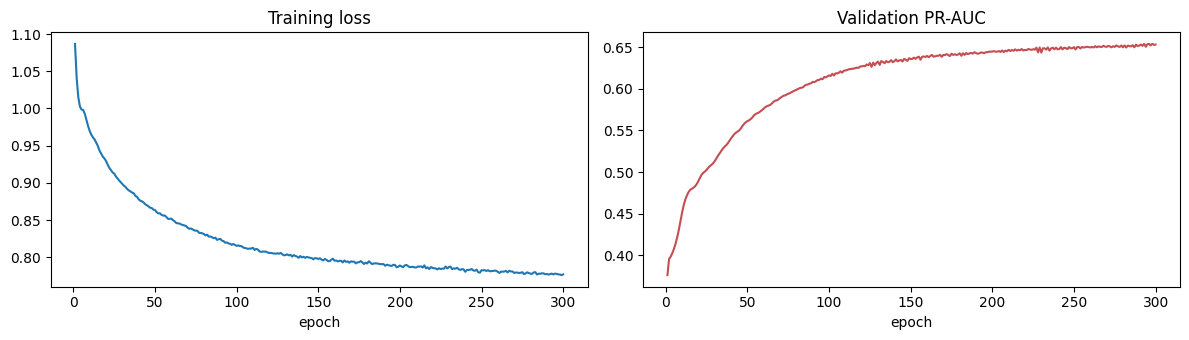

In [17]:
if not HAS_TORCH:
    raise ImportError("PyTorch is required for this section. See the install hint printed in the setup cell.")

def to_torch_sparse(M):
    M = M.tocoo()
    idx = torch.from_numpy(np.vstack([M.row, M.col]).astype(np.int64))
    val = torch.from_numpy(M.data.astype(np.float32))
    return torch.sparse_coo_tensor(idx, val, M.shape).coalesce().to(DEVICE)

# one row-normalised adjacency per relation type (built in the feature section)
adjs = [to_torch_sparse(M) for M in A_rel_row]
print(f"Adjacency matrices built: {len(adjs)} (one per relation)")


class RelSAGE(nn.Module):
    def __init__(self, in_dim, hidden, n_layers, n_rel, dropout):
        super().__init__()
        dims = [in_dim] + [hidden] * (n_layers - 1) + [1]
        self.layers = nn.ModuleList([nn.Linear(dims[i] * (1 + n_rel), dims[i + 1]) for i in range(n_layers)])
        self.dropout = dropout

    def forward(self, x, adjs):
        h = x
        for i, lin in enumerate(self.layers):
            h = lin(torch.cat([h] + [torch.sparse.mm(a, h) for a in adjs], dim=1))
            if i < len(self.layers) - 1:
                h = F.dropout(F.relu(h), self.dropout, self.training)
        return h.squeeze(-1)


X_t = torch.from_numpy(X_std).to(DEVICE)
y_t = torch.from_numpy(np.where(y >= 0, y, 0).astype(np.float32)).to(DEVICE)
tr_t, va_t = torch.from_numpy(tr_idx).to(DEVICE), torch.from_numpy(va_idx).to(DEVICE)

pos_weight = float(np.clip((y[tr_idx] == 0).sum() / max((y[tr_idx] == 1).sum(), 1), 1, 50))
model = RelSAGE(X_std.shape[1], HIDDEN, N_LAYERS, len(adjs), DROPOUT).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, device=DEVICE))

history, best_ap, best_state, bad = [], -1.0, None, 0
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    optimizer.zero_grad()
    out = model(X_t, adjs)
    loss = loss_fn(out[tr_t], y_t[tr_t])
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_logit = model(X_t, adjs)[va_t].cpu().numpy()
    ap = average_precision_score(y[va_idx], val_logit)
    history.append((epoch, loss.item(), ap))

    if ap > best_ap:
        best_ap, bad = ap, 0
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    else:
        bad += 1
    if epoch % 10 == 0 or epoch == 1:
        print(f"epoch {epoch:3d} | loss {loss.item():.4f} | val PR-AUC {ap:.4f} | best {best_ap:.4f} | {time.time() - t0:.0f}s")
    if bad >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best val PR-AUC {best_ap:.4f})")
        break

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    gnn_logit = model(X_t, adjs).cpu().numpy()

hist = pd.DataFrame(history, columns=["epoch", "loss", "val_pr_auc"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(hist["epoch"], hist["loss"]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_pr_auc"], color="#c44e52"); ax[1].set_title("Validation PR-AUC"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 13. Ensemble: GNN + Gradient Boosting + Naive Bayes

The three models score on very different scales, so each score is converted to a **percentile rank using the validation set as reference**. Then:

* **Weighted soft vote:** `score = w_gnn * GNN + w_gbm * GBM + w_nb * NB`, with the weights (summing to 1) searched on the validation set.
* **Stacked (optional):** a small logistic regression on the three raw scores, trained on the validation set. Its validation numbers are optimistic because it was fitted there; judge it on the test set.

For every model the decision threshold is picked on validation to maximise F1, then applied unchanged to the test set.

In [18]:
def ecdf_scores(reference, values):
    ref = np.sort(reference)
    return np.searchsorted(ref, values, side="right") / len(ref)

r_nb = ecdf_scores(nb_logit[va_idx], nb_logit)
r_gbm = ecdf_scores(gbm_logit[va_idx], gbm_logit)
r_gnn = ecdf_scores(gnn_logit[va_idx], gnn_logit)

grid = np.round(np.linspace(0, 1, 11), 2)
combos = [(a, b, round(1 - a - b, 2)) for a in grid for b in grid if a + b <= 1.0 + 1e-9]
combo_ap = [average_precision_score(y[va_idx], (a * r_gnn + b * r_gbm + c * r_nb)[va_idx]) for a, b, c in combos]
w_gnn, w_gbm, w_nb = combos[int(np.argmax(combo_ap))]
ens_score = w_gnn * r_gnn + w_gbm * r_gbm + w_nb * r_nb
ENS_NAME = f"Ensemble (GNN {w_gnn:.1f} / GBM {w_gbm:.1f} / NB {w_nb:.1f})"
print(f"Best weights on validation: GNN {w_gnn:.1f}, GBM {w_gbm:.1f}, NB {w_nb:.1f} (val PR-AUC {max(combo_ap):.4f})")

top_c = sorted(zip(combo_ap, combos), reverse=True)[:5]
print("Top 5 weight combinations (val PR-AUC, [gnn, gbm, nb]):")
for ap, c in top_c:
    print(f"  {ap:.4f}  {c}")

# stacked variant
stack_feats = np.column_stack([np.clip(nb_logit, -50, 50), gbm_logit, gnn_logit])
stack_scaler = StandardScaler().fit(stack_feats[va_idx])
stacker = LogisticRegression(class_weight="balanced", max_iter=1000)
stacker.fit(stack_scaler.transform(stack_feats[va_idx]), y[va_idx])
stack_score = stacker.decision_function(stack_scaler.transform(stack_feats))
print("Stacker coefficients [NB, GBM, GNN]:", np.round(stacker.coef_[0], 3))

Best weights on validation: GNN 0.1, GBM 0.9, NB 0.0 (val PR-AUC 0.8346)
Top 5 weight combinations (val PR-AUC, [gnn, gbm, nb]):
  0.8346  (np.float64(0.1), np.float64(0.9), np.float64(0.0))
  0.8321  (np.float64(0.2), np.float64(0.8), np.float64(0.0))
  0.8309  (np.float64(0.0), np.float64(1.0), np.float64(0.0))
  0.8251  (np.float64(0.3), np.float64(0.7), np.float64(0.0))
  0.8244  (np.float64(0.1), np.float64(0.8), np.float64(0.1))
Stacker coefficients [NB, GBM, GNN]: [-0.11   2.129  0.576]


## 14. Evaluation on the held-out test set

Accuracy is meaningless here (predicting "nobody is an abuser" is already >95% accurate), so the table reports:

* **Precision**: of the users we flag, how many really are abusers (cost of wrongly blocking customers)
* **Recall**: of all abusers, how many we catch (money still lost)
* **F1**: balance of the two
* **PR-AUC**: threshold-free quality, the main metric for rare-event problems
* **ROC-AUC**: threshold-free ranking quality (can look flattering when positives are rare)
* **Precision@K**: precision among the K highest-scored test users, where K = number of real abusers in the test set
* **Accuracy / balanced accuracy**: shown for completeness. When abusers are a minority, compare accuracy with the trivial baseline printed above the table
* **Lift**: precision divided by the abuser base rate (1.0 = no better than random flagging)

In [19]:
def best_threshold(y_val, s_val):
    p, r, t = precision_recall_curve(y_val, s_val)
    f1 = 2 * p * r / np.maximum(p + r, 1e-12)
    return float(t[int(np.argmax(f1[:-1]))])

def evaluate(name, score):
    thr = best_threshold(y[va_idx], score[va_idx])
    yt, st = y[te_idx], score[te_idx]
    pred = (st >= thr).astype(int)
    k = int(yt.sum())
    top_k = np.argsort(-st)[:k]
    prec = precision_score(yt, pred, zero_division=0)
    rec = recall_score(yt, pred, zero_division=0)
    return {
        "model": name,
        "val_pr_auc": average_precision_score(y[va_idx], score[va_idx]),
        "threshold": thr,
        "precision": prec,
        "recall": rec,
        "f1": f1_score(yt, pred, zero_division=0),
        "pr_auc": average_precision_score(yt, st),
        "roc_auc": roc_auc_score(yt, st),
        "accuracy": float((pred == yt).mean()),
        "balanced_acc": (rec + float(((pred == 0) & (yt == 0)).sum() / max((yt == 0).sum(), 1))) / 2,
        "lift": prec / max(float(yt.mean()), 1e-12),
        "precision@K": yt[top_k].mean(),
        "flagged": int(pred.sum()),
    }

scores = {
    "Naive Bayes": nb_logit,
    "Gradient Boosting": gbm_logit,
    "GNN (relation-aware SAGE)": gnn_logit,
    ENS_NAME: ens_score,
    "Ensemble (stacked LR)": stack_score,
}
results = pd.DataFrame([evaluate(n, s) for n, s in scores.items()])
base_rate = float(y[te_idx].mean())
print(f"Test set: {len(te_idx):,} users, {int(y[te_idx].sum()):,} abusers (base rate {base_rate:.3f}).")
print(f"Baseline to beat: predicting 'normal' for everyone gives accuracy {1 - base_rate:.3f} and recall 0.")
print(f"A random model has PR-AUC about {base_rate:.3f}. 'lift' = precision / base rate (1.0 = no better than chance).\n")
display(results.round(4).set_index("model"))

Test set: 77,169 users, 17,517 abusers (base rate 0.227).
Baseline to beat: predicting 'normal' for everyone gives accuracy 0.773 and recall 0.
A random model has PR-AUC about 0.227. 'lift' = precision / base rate (1.0 = no better than chance).



,val_pr_auc,threshold,precision,recall,f1,pr_auc,roc_auc,accuracy,balanced_acc,lift,precision@K,flagged
model,,,,,,,,,,,,
Naive Bayes,0.3643,0.6124,0.3339,0.5619,0.4189,0.3620,0.6687,0.6461,0.6164,1.4710,0.3702,29474
Gradient Boosting,0.8309,0.7916,0.7782,0.6899,0.7314,0.8310,0.9184,0.8850,0.8161,3.4284,0.7343,15529
GNN (relation-aware SAGE),0.6539,0.3718,0.5726,0.6422,0.6054,0.6612,0.8404,0.8100,0.7507,2.5227,0.6032,19646
Ensemble (GNN 0.1 / GBM 0.9 / NB 0.0),0.8346,0.7684,0.7630,0.7135,0.7374,0.8357,0.9209,0.8847,0.8242,3.3614,0.7383,16381
Ensemble (stacked LR),0.8359,0.7431,0.7559,0.7228,0.7390,0.8366,0.9227,0.8841,0.8271,3.3298,0.7376,16752


Final model (best validation PR-AUC): Ensemble (stacked LR)


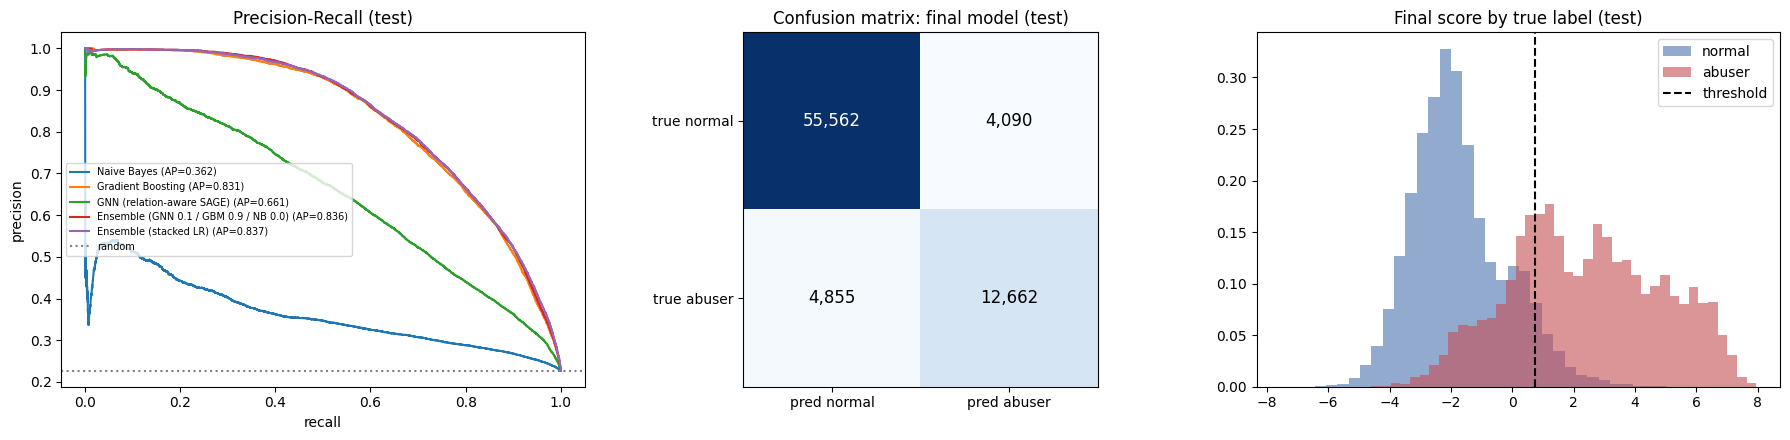

Final model at the validation-tuned threshold:
  caught 12,662 of 17,517 abusers (recall 72.3%), flagged 16,752 users (precision 75.6%, lift 3.3x); 4,090 normal users wrongly flagged.


In [20]:
# The final model is chosen on VALIDATION PR-AUC (never on the test set)
FINAL_NAME = results.sort_values("val_pr_auc").iloc[-1]["model"]
final_score = scores[FINAL_NAME]
final_thr = float(results.loc[results["model"] == FINAL_NAME, "threshold"].iloc[0])
print("Final model (best validation PR-AUC):", FINAL_NAME)

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))

for name, sc in scores.items():
    p, r, _ = precision_recall_curve(y[te_idx], sc[te_idx])
    ax[0].plot(r, p, label=f"{name} (AP={average_precision_score(y[te_idx], sc[te_idx]):.3f})")
ax[0].axhline(base_rate, color="grey", ls=":", label="random")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-Recall (test)")
ax[0].legend(fontsize=7)

cm = confusion_matrix(y[te_idx], (final_score[te_idx] >= final_thr).astype(int))
ax[1].imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax[1].text(j, i, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["pred normal", "pred abuser"])
ax[1].set_yticks([0, 1]); ax[1].set_yticklabels(["true normal", "true abuser"])
ax[1].set_title("Confusion matrix: final model (test)")

for lbl, name, col in [(0, "normal", "#4c72b0"), (1, "abuser", "#c44e52")]:
    ax[2].hist(final_score[te_idx][y[te_idx] == lbl], bins=40, alpha=0.6, density=True, label=name, color=col)
ax[2].axvline(final_thr, color="k", ls="--", label="threshold")
ax[2].set_title("Final score by true label (test)"); ax[2].legend()
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Final model at the validation-tuned threshold:")
print(f"  caught {tp:,} of {tp + fn:,} abusers (recall {tp / max(tp + fn, 1):.1%}), flagged {tp + fp:,} users "
      f"(precision {tp / max(tp + fp, 1):.1%}, lift {tp / max(tp + fp, 1) / base_rate:.1f}x); "
      f"{fp:,} normal users wrongly flagged.")

## 15. What distinguishes abusers? (interpretation + error analysis)

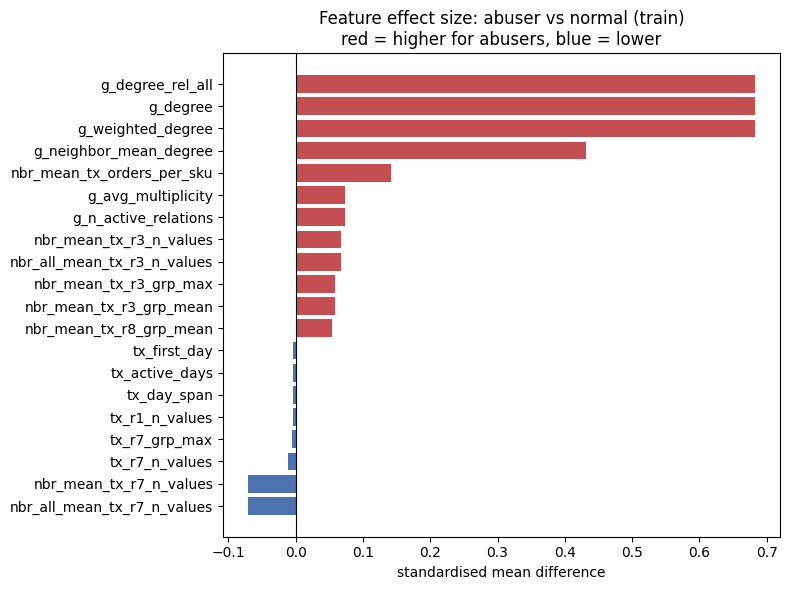

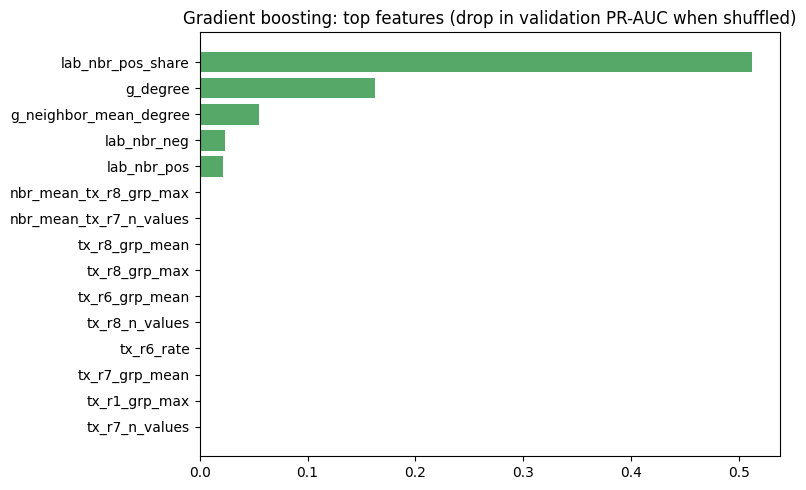

Top 20 most suspicious users in the test set:


,user_id,ensemble_score,gnn_rank_score,gbm_rank_score,nb_rank_score,degree,true_label
20081,2718305,7.952097,0.999134,0.999289,0.870513,85.0,1
43832,1085681,7.952097,0.999134,0.999289,0.870513,85.0,1
38775,1156158,7.952097,0.999134,0.999289,0.870513,85.0,1
69868,612874,7.952097,0.999134,0.999289,0.870513,85.0,1
20545,2026092,7.928853,0.999134,0.999289,0.866825,85.0,1
57536,847729,7.927361,0.999134,0.999289,0.866781,85.0,1
8486,363536,7.925135,0.999111,0.999467,0.870246,85.0,1
43979,1894079,7.896163,0.999089,0.999289,0.867181,85.0,1
11398,290512,7.886353,0.999911,0.995646,0.939022,52.0,1
67738,2766245,7.859494,0.999134,0.999289,0.976275,86.0,1


Abusers among the top 20: 20/20

Missed abusers: 4855 | their median degree = 8 vs 10 for all abusers.
Typical reason: abusers with few connections give the graph little to work with.


In [21]:
# standardised mean difference (abuser vs normal) on the TRAIN set
Xtr_pos, Xtr_neg = X_raw[tr_idx][y[tr_idx] == 1], X_raw[tr_idx][y[tr_idx] == 0]
pooled = np.sqrt((Xtr_pos.var(0) + Xtr_neg.var(0)) / 2) + 1e-9
effect = pd.Series((Xtr_pos.mean(0) - Xtr_neg.mean(0)) / pooled, index=feature_names).sort_values()
top = pd.concat([effect.head(8), effect.tail(12)])

plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=["#4c72b0" if v < 0 else "#c44e52" for v in top.values])
plt.axvline(0, color="k", lw=0.8)
plt.title("Feature effect size: abuser vs normal (train)\nred = higher for abusers, blue = lower")
plt.xlabel("standardised mean difference"); plt.tight_layout(); plt.show()

# permutation importance of the boosting model on a validation sample (what does it rely on?)
rng_pi = np.random.default_rng(SEED)
pi_idx = rng_pi.choice(va_idx, size=min(6000, len(va_idx)), replace=False)
pi = permutation_importance(gbm, X_gbm[pi_idx], y[pi_idx], scoring="average_precision",
                            n_repeats=3, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=gbm_feature_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(8, 5))
plt.barh(imp.index[::-1], imp.values[::-1], color="#55a868")
plt.title("Gradient boosting: top features (drop in validation PR-AUC when shuffled)")
plt.tight_layout(); plt.show()

# most suspicious test users
node_ids = index.to_numpy()
top_df = pd.DataFrame({
    "user_id": node_ids[te_idx],
    "ensemble_score": final_score[te_idx],
    "gnn_rank_score": r_gnn[te_idx],
    "gbm_rank_score": r_gbm[te_idx],
    "nb_rank_score": r_nb[te_idx],
    "degree": deg[te_idx],
    "true_label": y[te_idx],
}).sort_values("ensemble_score", ascending=False)
print("Top 20 most suspicious users in the test set:")
display(top_df.head(20))
print(f"Abusers among the top 20: {int(top_df.head(20)['true_label'].sum())}/20")

# missed abusers
missed = top_df[(top_df["true_label"] == 1) & (top_df["ensemble_score"] < final_thr)]
print(f"\nMissed abusers: {len(missed)} | their median degree = {missed['degree'].median():.0f} "
      f"vs {top_df[top_df['true_label'] == 1]['degree'].median():.0f} for all abusers.")
print("Typical reason: abusers with few connections give the graph little to work with.")

## 16. Save results

In [22]:
import joblib

results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
top_df.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)
torch.save(best_state, OUTPUT_DIR / "gnn_best.pt")
joblib.dump({"quantile_transformer": qt, "naive_bayes": nb, "feature_names": feature_names}, OUTPUT_DIR / "naive_bayes.joblib")
joblib.dump({"model": gbm, "feature_names": gbm_feature_names}, OUTPUT_DIR / "gradient_boosting.joblib")

run_config = {
    "split_mode": mode, "n_nodes": int(N), "n_features": int(X_raw.shape[1]), "relations": rel_names,
    "detected_columns": {"node_id": NODE_ID, "label": LABEL, "edge_src": SRC, "edge_dst": DST,
                         "edge_rel": EDGE_REL, "edge_rel_multi": EDGE_REL_MULTI},
    "max_nodes": MAX_NODES, "preserve_prevalence": PRESERVE_PREVALENCE, "tx_max_rows": TX_MAX_ROWS,
    "gnn": {"hidden": HIDDEN, "layers": N_LAYERS, "dropout": DROPOUT, "lr": LR, "pos_weight": pos_weight},
    "ensemble_weights": {"gnn": w_gnn, "gbm": w_gbm, "nb": w_nb}, "final_model": FINAL_NAME,
    "label_neighbor_features": USE_LABEL_NEIGHBOR_FEATURES, "seed": SEED,
}
(OUTPUT_DIR / "run_config.json").write_text(json.dumps(run_config, indent=2))
print("Saved to", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print("  ", p.name)

Saved to D:\LEARNING_HOW_TO_CODE\Public_offer_Abuse\outputs
   gnn_best.pt
   gradient_boosting.joblib
   model_comparison.csv
   naive_bayes.joblib
   run_config.json
   test_predictions.csv
   tx_feat_test.pkl
   tx_feat_train.pkl


## 17. Summary and how to present it

**Problem.** Promotion abuse looks like normal shopping per user, so single-account models struggle. Abusers are linked: they share relation values (group chats, coupons, dealers...) with other accounts.

**Approach.**
1. Streamed ~40M order lines into per-user, per-week behaviour features, including *how many other users share each relation value* (group-size features).
2. Built a multi-relation user graph from `edge.csv`.
3. Model A: Gaussian Naive Bayes on tabular + structural features (fast, simple baseline).
4. Model B: gradient boosting on the same features plus label-aware neighbour features (train labels only).
5. Model C: relation-aware GraphSAGE that passes messages separately per relation type.
6. Ensemble: percentile-rank soft vote with the three weights tuned on validation, and a stacked variant. The final model is the one with the best **validation** PR-AUC.
7. Evaluated with a **temporal split** (train on week 1, test on users from week 2) using PR-AUC, precision, recall, F1, and lift over the base rate.

**Design choices to defend in a viva**
* *Why PR-AUC and not accuracy?* Abusers are rare; "predict nobody" is already ~99% accurate.
* *Why a temporal split?* It tests generalisation to future users and avoids leaking week-2 behaviour into training.
* *Why log1p + quantile transform for Naive Bayes?* Count features are heavily skewed, which violates the Gaussian assumption.
* *Why ensemble?* Boosting is strong on per-user behaviour and handles skewed counts; the GNN adds neighbourhood context; NB is a simple baseline. Their errors differ, so combining can help (check the table for whether it did in your run).
* *Why is accuracy not the headline?* When abusers are, say, a quarter of users, predicting "normal" for everyone already scores about 75% accuracy. Compare accuracy against that baseline and look at precision, recall, PR-AUC and lift.
* *Leakage control.* Features 1 to 3 use no labels. The label-aware neighbour features use training labels only and go to the boosting model only (not the GNN, where message passing would leak a node's own label). Neighbourhood-feature selection and all scalers use training nodes only. Threshold and ensemble weight use validation only. Users active in both weeks are kept out of the test set.

**Known limitations (state these honestly).**
* Sub-sampling to `MAX_NODES` thins the graph; metrics on the sample are not identical to the full dataset.
* Labels come from reported cases, so some undetected abusers are labelled "normal" (label noise).
* Full-batch GNN training does not scale to millions of nodes without neighbour sampling.
* The published PromoGuardian model uses richer edge features (spatial and temporal weights); this notebook is a simpler, course-sized version.

**Ideas to extend.** Add temporal edge weights; try GAT-style attention; tune the decision threshold to a business cost (cost of a lost promotion vs cost of blocking a real customer); run on the full graph with neighbour sampling.

**Link back to your original idea.** Replace "promotion" by "free trial" and "shared coupon / address / group" by "shared device / IP / payment card / email pattern": the same graph-plus-tabular approach carries over.